# 1 · Exploration des données et modèle Data Science (TF-IDF)

**Objectif du projet** : à partir du **titre** d'une question Stack Overflow, prédire automatiquement ses **tags** (`python`, `c#`, `sql`…).

C'est un problème de **classification multi-label** : une question peut avoir plusieurs tags à la fois.

Ce notebook :
1. explore le jeu de données ;
2. prépare les données (le même découpage servira pour BERT) ;
3. entraîne et évalue un modèle classique **TF-IDF + régression logistique**.

> Le code « réutilisable » est dans le dossier `src/` ; ce notebook l'appelle et explique la démarche.

In [1]:
import os, sys
if "google.colab" in sys.modules:  # exécution sur Google Colab : on récupère le projet depuis GitHub
    REPO_URL = "https://github.com/TON_PSEUDO/stackoverflow-tag-prediction.git"  # <-- à remplacer par ton repo
    REPO_DIR = REPO_URL.rstrip("/").split("/")[-1].removesuffix(".git")
    if not os.path.exists(REPO_DIR):
        !git clone -q {REPO_URL}
    %cd {REPO_DIR}
    !pip install -q iterative-stratification
elif not os.path.exists("src"):  # exécution locale depuis le dossier notebooks/
    os.chdir("..")
print("Dossier de travail :", os.getcwd())

Dossier de travail : C:\Users\Emili\Documents\Professionnel\Cours\EPF 5A\From Poc to Prod\TP1


In [2]:
import numpy as np
import pandas as pd

from src.preprocessing import DATA_PATH, MIN_TAG_COUNT, clean_title, filter_frequent_tags, load_posts, prepare_dataset
import matplotlib.pyplot as plt

BLUE, ORANGE = "#2a78d6", "#eb6834"  # couleur 1 = TF-IDF / série unique, couleur 2 = BERT
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 11,
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
})

## 1. Les données brutes

Le fichier contient **une ligne par couple (question, tag)** : une question avec 3 tags apparaît donc sur 3 lignes.

In [3]:
raw = pd.read_csv(DATA_PATH)
print(raw.shape)
raw.head(8)

(9999, 5)


,post_id,tag_name,tag_id,tag_position,title
0,1987528,php,5,0,Is it possible to execute the procedure of a f...
1,1987531,ruby-on-rails,4984,0,ruby on rails: how to change BG color of optio...
2,1987531,list,5608,1,ruby on rails: how to change BG color of optio...
3,1987531,select,1151,2,ruby on rails: how to change BG color of optio...
4,1987538,c#,9,0,How to read tags out of m4a files in .NET?
5,1987538,.net,1,1,How to read tags out of m4a files in .NET?
6,1987538,tags,115,2,How to read tags out of m4a files in .NET?
7,1987541,c#,9,0,Cannot marshal a struct that contains a union


On regroupe par question pour obtenir **un titre + une liste de tags** :

In [4]:
posts = load_posts()
print(f"{len(posts)} questions, {posts.tags.explode().nunique()} tags différents")
posts.head()

4609 questions, 681 tags différents


,post_id,title,tags
0,1987528,Is it possible to execute the procedure of a f...,[php]
1,1987531,ruby on rails: how to change BG color of optio...,"[ruby-on-rails, list, select]"
2,1987538,How to read tags out of m4a files in .NET?,"[c#, .net, tags]"
3,1987541,Cannot marshal a struct that contains a union,"[c#, c++, struct]"
4,1987542,libSVM automated labeller script,"[sed, awk]"


## 2. Exploration

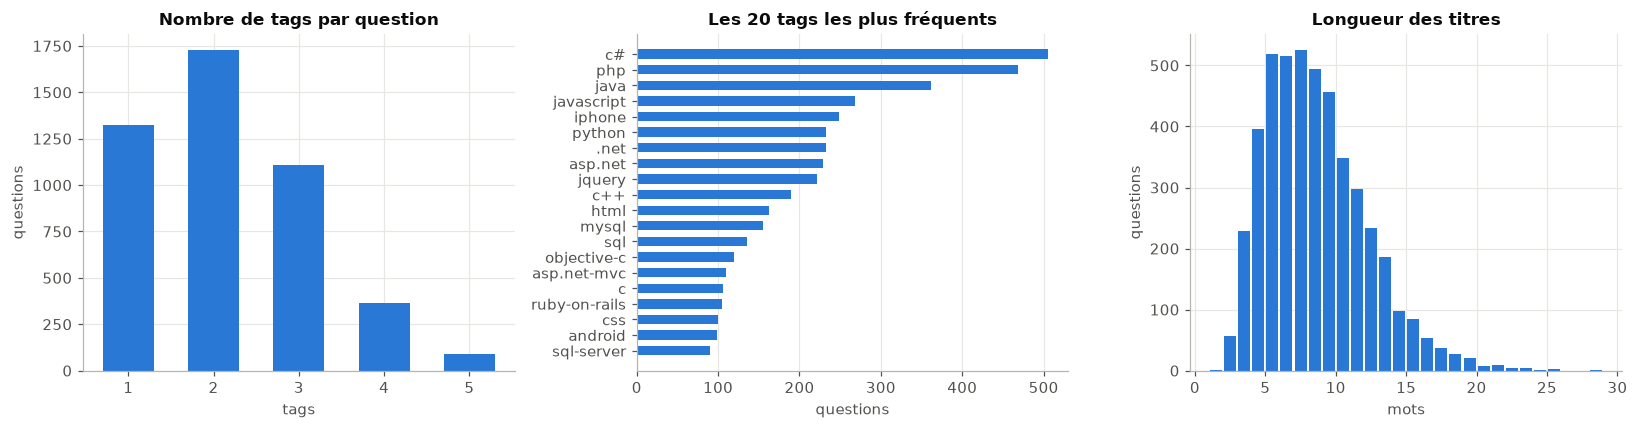

Titre moyen : 8.1 mots


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

n_tags = posts.tags.str.len().value_counts().sort_index()
axes[0].bar(n_tags.index, n_tags.values, color=BLUE, width=0.6)
axes[0].set(title="Nombre de tags par question", xlabel="tags", ylabel="questions")

top = posts.tags.explode().value_counts().head(20)[::-1]
axes[1].barh(top.index, top.values, color=BLUE, height=0.6)
axes[1].set(title="Les 20 tags les plus fréquents", xlabel="questions")
axes[1].grid(axis="y", visible=False)

lengths = posts.title.str.split().str.len()
axes[2].hist(lengths, bins=range(1, 30), color=BLUE, rwidth=0.85)
axes[2].set(title="Longueur des titres", xlabel="mots", ylabel="questions")
plt.tight_layout(); plt.show()

print(f"Titre moyen : {lengths.mean():.1f} mots")

**Constats**
- en moyenne ~2 tags par question → bien du multi-label ;
- les titres sont **très courts** (~8 mots) : peu d'information à exploiter ;
- **longue traîne** : quelques tags très fréquents (`c#`, `php`, `java`), la plupart très rares.

Un tag vu 2 fois ne peut pas être appris. On ne garde donc que les tags assez fréquents. Voici le compromis selon le seuil :

In [6]:
rows = []
for m in [5, 10, 20, 30, 50]:
    f, kept = filter_frequent_tags(posts, m)
    rows.append({"seuil (occurrences min.)": m, "tags gardés": len(kept),
                 "questions gardées": len(f), "% questions gardées": round(100 * len(f) / len(posts), 1)})
pd.DataFrame(rows)

,seuil (occurrences min.),tags gardés,questions gardées,% questions gardées
0,5,392,4547,98.7
1,10,201,4409,95.7
2,20,86,4100,89.0
3,30,55,3891,84.4
4,50,33,3622,78.6


On choisit **au moins 20 occurrences** : ~86 tags et ~89 % des questions conservées.

## 3. Préparation : découpage train / validation / test

- **train (70 %)** : les exemples pour apprendre ;
- **validation (15 %)** : pour régler les paramètres ;
- **test (15 %)** : l'« examen final », jamais vu pendant l'entraînement.

Le découpage est **stratifié multi-label** : chaque tag est présent dans les mêmes proportions dans les 3 parties. Il est fixé (`seed=42`) : BERT utilisera **exactement le même**.

In [7]:
train_df, val_df, test_df, mlb = prepare_dataset()
print(f"train={len(train_df)}  val={len(val_df)}  test={len(test_df)}  tags={len(mlb.classes_)}")

# Les tags deviennent un vecteur de 0/1 (une colonne par tag)
print(train_df.tags[0], "->", np.flatnonzero(mlb.transform([train_df.tags[0]])[0]))

train=2866  val=623  test=611  tags=86
['php'] -> [56]


## 4. Le modèle TF-IDF expliqué

**1) Transformer le texte en nombres (TF-IDF).** Chaque titre devient un vecteur : un score par mot. Le score est élevé si le mot est **présent dans ce titre** mais **rare dans l'ensemble** (un mot comme *mysql* est très informatif, *how* ne l'est pas).

On combine deux vues :
- les **mots** et paires de mots (`list comprehension`) ;
- les **morceaux de 2 à 5 caractères** (`jque`, `query`) : robuste aux variantes et fautes de frappe.

Le nettoyage garde volontairement `#`, `+` et `.` pour ne pas confondre `c`, `c#` et `c++`.

In [8]:
for t in ["How to use C# with .NET?", "C++ vs Java!!", "asp.net-mvc routing... help"]:
    print(f"{t!r:35} -> {clean_title(t)!r}")

'How to use C# with .NET?'          -> 'how to use c# with .net'
'C++ vs Java!!'                     -> 'c++ vs java'
'asp.net-mvc routing... help'       -> 'asp.net-mvc routing help'


**2) Classer.** Pour chaque tag, une **régression logistique** apprend « ce titre a-t-il ce tag ? » et donne une probabilité (86 tags → 86 petits modèles, `OneVsRest`).

**3) Optimisations**
- `class_weight="balanced"` : les tags rares comptent autant que les fréquents ;
- **régularisation `C`** choisie sur la validation ;
- **seuil de décision optimisé** sur la validation (au lieu de 0,5) ;
- **au moins un tag** prédit par question.

Variantes testées et écartées (moins bonnes sur la validation) : SVM linéaire, régression logistique sans rééquilibrage.

## 5. Entraînement et évaluation

In [9]:
from src.tfidf_model import train

tfidf_metrics = train()

C=  0.3  seuil=0.61  F1 micro (val)=0.5451


C=    1  seuil=0.68  F1 micro (val)=0.5510


C=    3  seuil=0.62  F1 micro (val)=0.5471


C=   10  seuil=0.56  F1 micro (val)=0.5443



Résultats sur le test : {
  "f1_micro": 0.5611,
  "f1_macro": 0.5123,
  "precision_micro": 0.6156,
  "recall_micro": 0.5155,
  "precision_at_1": 0.6547,
  "hamming_loss": 0.0148,
  "threshold": 0.68,
  "best_C": 1,
  "n_tags": 86,
  "train_time_s": 8.3,
  "inference_ms_per_question": 0.215,
  "model_size_mb": 13.5
}


### Comprendre les métriques
| Métrique | Signification |
|---|---|
| **F1 micro** (principale) | compromis entre précision et rappel, sur l'ensemble des tags prédits |
| F1 macro | moyenne du F1 de chaque tag : pénalise si les tags rares sont mal prédits |
| Précision | parmi les tags prédits, combien sont corrects |
| Rappel | parmi les vrais tags, combien ont été retrouvés |
| Précision@1 | le tag jugé le plus probable est-il correct ? |
| Hamming loss | proportion de cases (question × tag) mal prédites (plus bas = mieux) |

## 6. Analyse des résultats

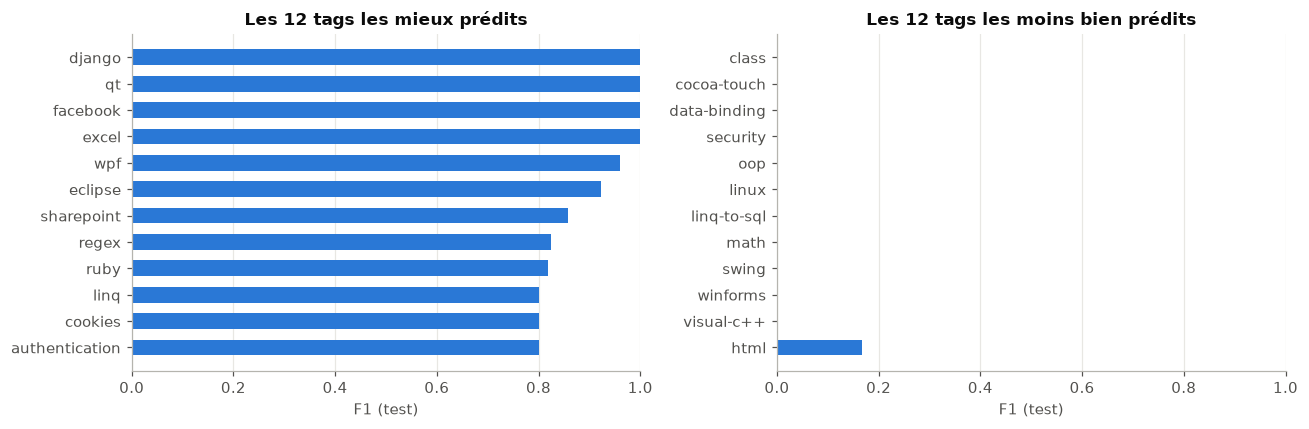

In [10]:
import joblib
from sklearn.metrics import f1_score
from src.metrics import scores_to_labels
from src.tfidf_model import MODEL_PATH

bundle = joblib.load(MODEL_PATH)
model, threshold = bundle["model"], bundle["threshold"]
y_test = mlb.transform(test_df.tags)
test_scores = model.predict_proba(test_df.title)
y_pred = scores_to_labels(test_scores, threshold)

per_tag = pd.Series(f1_score(y_test, y_pred, average=None, zero_division=0), index=mlb.classes_).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for ax, data, title in [(axes[0], per_tag.tail(12), "Les 12 tags les mieux prédits"),
                        (axes[1], per_tag.head(12)[::-1], "Les 12 tags les moins bien prédits")]:
    ax.barh(data.index, data.values, color=BLUE, height=0.6)
    ax.set(title=title, xlabel="F1 (test)", xlim=(0, 1)); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

Les tags **spécifiques** (un nom de langage ou d'outil qui apparaît dans le titre) sont très bien prédits. Les tags **génériques** (`class`, `oop`, `security`, `linux`, `math`…) sont difficiles : le mot n'est souvent pas dans le titre. Attention : les tags rares n'ont que 3-4 exemples dans le test, leur score est donc très variable.

### Quels mots le modèle utilise-t-il ?

In [11]:
features = model.named_steps["tfidf"].get_feature_names_out()
word_idx = np.array([f.startswith("words__") for f in features])
estimators = model.named_steps["clf"].estimators_

rows = {}
for tag in ["python", "javascript", "sql", "iphone", "c#", "css"]:
    coefs = estimators[list(mlb.classes_).index(tag)].coef_.ravel()
    best = np.argsort(-np.where(word_idx, coefs, -np.inf))[:8]
    rows[tag] = [features[i].removeprefix("words__") for i in best]
pd.DataFrame(rows)

,python,javascript,sql,iphone,c#,css
0,python,javascript,sql,iphone,c#,css
1,tkinter,js,tsql,be,in c#,div
2,module,jquery,tables,view,linq,direction
3,sqlalchemy,prototype,statement,warning,com,layout
4,pygame,div with,query,combining,issue,height
5,ssl,ff,row,orientation,webservice,jquery lavalamp
6,arguments,event,columns,sqlite,server and,lavalamp
7,mean,framework for,best database,uitableview,or,position


Le modèle a appris des associations sensées (ex. `python` ← *tkinter*, *sqlalchemy*, *pygame* ; `sql` ← *tsql*, *query*, *row*). 

### Exemples de prédictions sur le test

In [12]:
ex = test_df.sample(10, random_state=1).copy()
ex_scores = model.predict_proba(ex.title)
ex_pred = scores_to_labels(ex_scores, threshold)
ex["prédits"] = [list(mlb.classes_[row.astype(bool)]) for row in ex_pred]
pd.set_option("display.max_colwidth", 80)
ex[["title", "tags", "prédits"]]

,title,tags,prédits
49,What type of errors actually happen with mySQL/PHP,"[php, mysql]","[mysql, php]"
237,Status strip and Time,[c#],[php]
195,How to concatenate two numbers in Objective-C,"[objective-c, xcode]","[objective-c, xcode]"
605,window.onready = function() Fails in IE,[javascript],[internet-explorer]
197,Custom Id column in the Fluent NH entity name,[nhibernate],[.net]
460,How to convert an existing ASP.NET project into MVC pattern?,"[asp.net, asp.net-mvc]","[asp.net, asp.net-mvc]"
457,require_once(../../path/to/script.php) failed to open stream permission denied,"[php, linux, security]",[iphone]
488,Calling/Inserting functions before jQuery's document.ready,"[javascript, jquery]",[jquery]
318,EL over Scriptlets,[java],[javascript]
119,Find all combinations of a given set of numbers,"[java, c, algorithm]",[math]


## 7. Conclusion

- Le modèle TF-IDF est **rapide** (quelques secondes d'entraînement, < 1 ms par prédiction) et **interprétable** (on voit les mots utilisés).
- Sa limite : il ne fait que **reconnaître des mots-clés**, sans comprendre le sens. Une question sur `performance` sans le mot *performance* lui échappe.
- C'est notre **référence (baseline)** à battre avec BERT → `02_bert_finetuning.ipynb`.

Pour utiliser le modèle en ligne de commande :
```bash
python -m src.predict "How to center a div with CSS?"
```